# Week 4 Optimum Progress and Calibration

Plot each week's actual output, saved expected best-so-far, and observed best-so-far for weeks 1-4. The saved expectations were made before each evaluation; measured outputs come from the imported weekly observations.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.visualisation import plot_calibration, plot_optimum_progress
# plt.style.use("seaborn-v0_8-whitegrid")

CURRENT_WEEK = 4
WEEKS = (1, 2, 3, 4)
FUNCTION_IDS = tuple(FUNCTION_SPECS)
SAVE_FIGURE = False

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


## 1. Best-so-far records

In [2]:
historical_results = history.records.loc[history.records.week.isin(WEEKS)].copy()
previous_best = historical_results.pivot(index="function_id", columns="week", values="previous_best").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
actual_outputs = historical_results.pivot(index="function_id", columns="week", values="observed_output").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
expected_outputs = historical_results.pivot(index="function_id", columns="week", values="expected_mean").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
stds = historical_results.pivot(index="function_id", columns="week", values="expected_std").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
expected_best = historical_results.pivot(index="function_id", columns="week", values="expected_best").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
observed_best = historical_results.pivot(index="function_id", columns="week", values="observed_best").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
residuals = historical_results.groupby("function_id").residual.apply(list).to_dict()

expected_shape = (len(FUNCTION_IDS), len(WEEKS))
for label, values in (("previous", previous_best), ("actual", actual_outputs), ("expected", expected_best), ("observed", observed_best)):
    if values.shape != expected_shape or not np.all(np.isfinite(values)):
        raise ValueError(f"{label} best-so-far values must be finite with shape {expected_shape}")

tolerance = 1e-9 * (1 + np.abs(previous_best))
if np.any(expected_best < previous_best - tolerance):
    raise ValueError("Expected best-so-far must not be below the previous best")
if np.any(observed_best < previous_best - tolerance):
    raise ValueError("Observed best-so-far must not be below the previous best")

validation_table = pd.DataFrame(
    {
        f"Week {week} {label}": values[:, week_index]
        for week_index, week in enumerate(WEEKS)
        for label, values in (("previous", previous_best), ("expected", expected_best), ("observed", observed_best))
    },
    index=[f"Function {function_id}" for function_id in FUNCTION_IDS],
).round(4)
display(validation_table)

,Week 1 previous,Week 1 expected,Week 1 observed,Week 2 previous,Week 2 expected,Week 2 observed,Week 3 previous,Week 3 expected,Week 3 observed,Week 4 previous,Week 4 expected,Week 4 observed
Function 1,0.0000,0.0012,0.0000,0.0000,0.0004,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Function 2,0.6112,0.6443,0.6112,0.6112,0.6321,0.6112,0.6112,0.6215,0.6112,0.6112,0.6112,0.6112
Function 3,-0.0348,-0.0197,-0.0059,-0.0059,0.0233,-0.0059,-0.0059,0.0164,-0.0059,-0.0059,0.0334,-0.0059
Function 4,-4.0255,-3.4646,-3.3364,-3.3364,-2.6195,-1.2696,-1.2696,-0.8258,0.6870,0.6870,0.7490,0.6870
Function 5,1088.8596,1090.5900,1397.5451,1397.5451,1720.3868,1588.5985,1588.5985,1611.7140,3949.3592,3949.3592,4111.4288,3949.3592
Function 6,-0.7143,-0.6695,-0.7143,-0.7143,-0.4368,-0.4670,-0.4670,-0.3857,-0.4670,-0.4670,-0.4290,-0.4670
Function 7,1.3650,1.3650,1.3650,1.3650,1.3710,2.3677,2.3677,2.3908,2.3677,2.3677,2.3931,2.3677
Function 8,9.5985,9.6188,9.5985,9.5985,9.8809,9.8811,9.8811,10.1249,9.8811,9.8811,10.0162,9.8930


## 2. Optimum progress

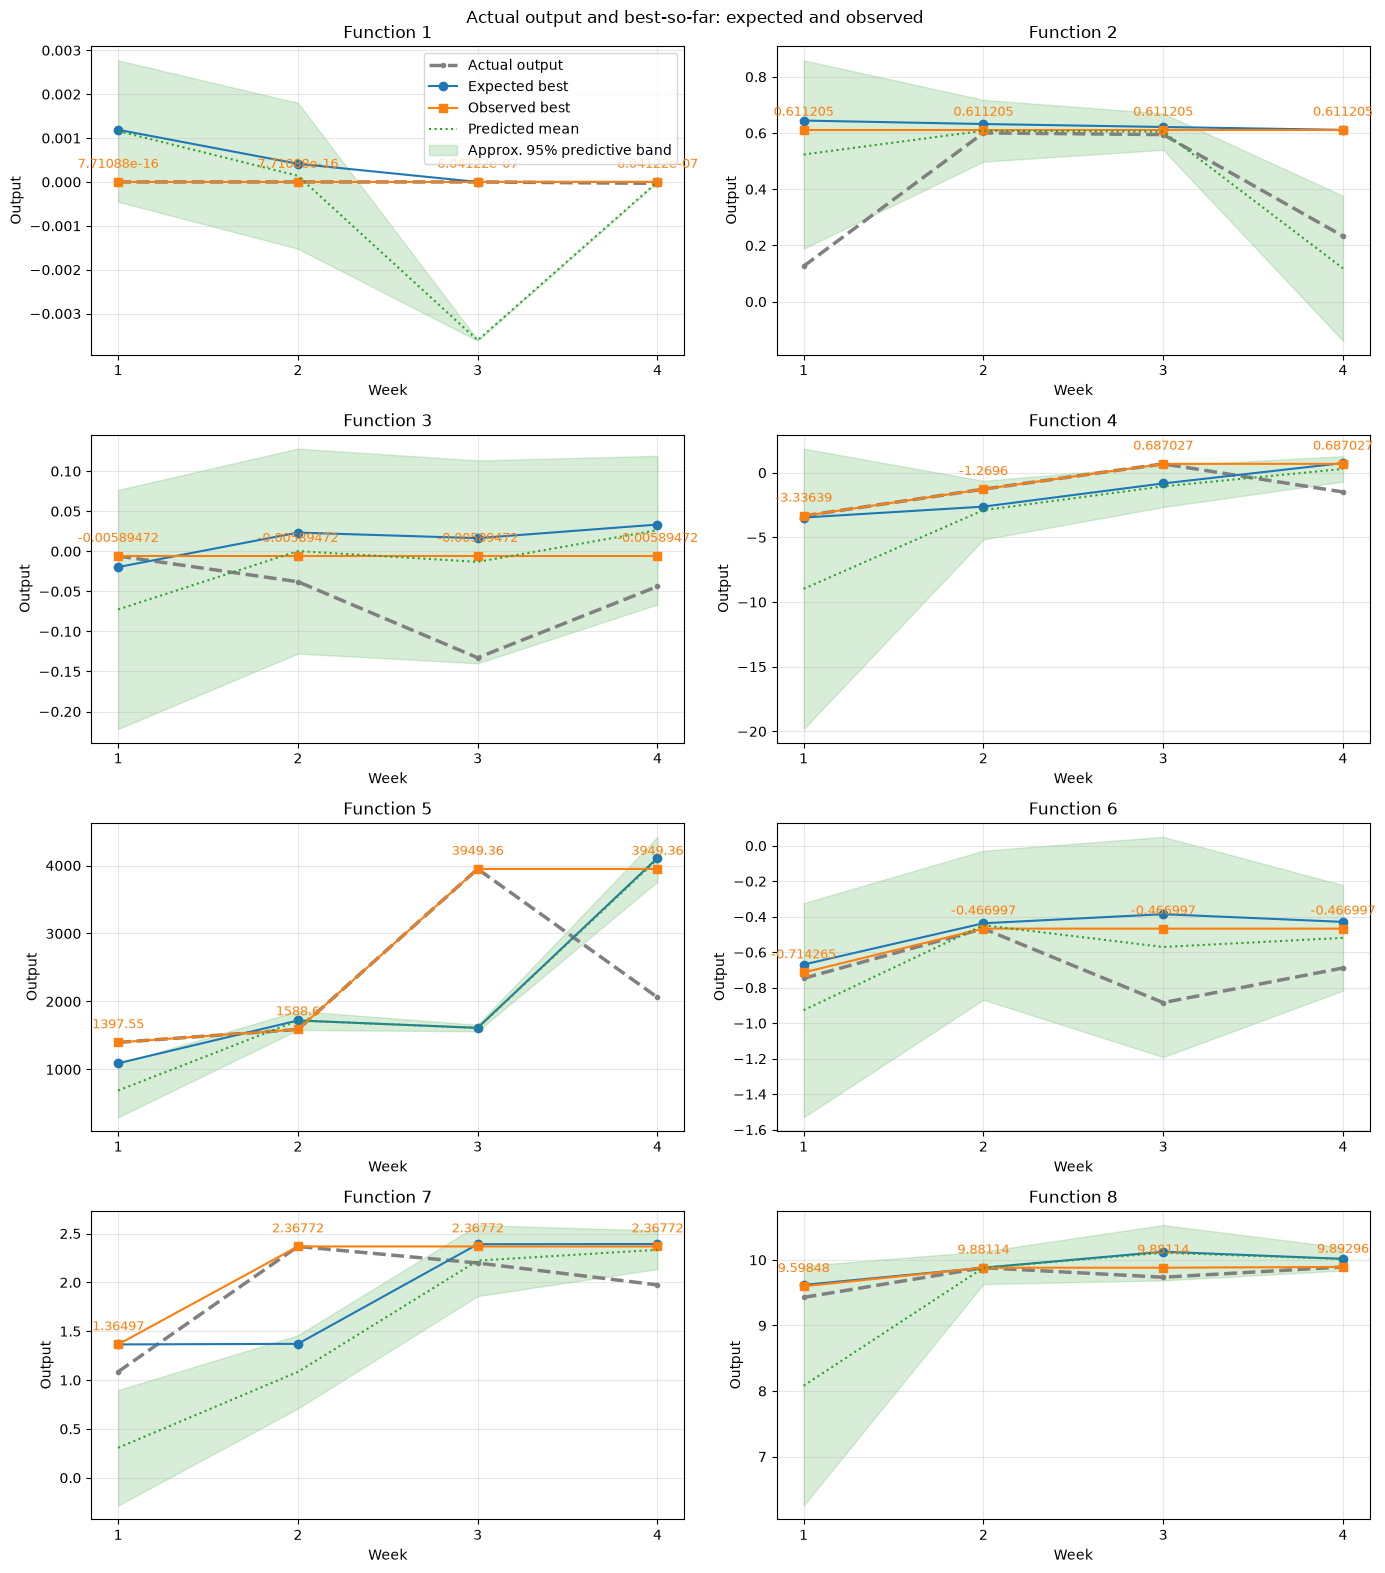

In [3]:
optimum_figure, optimum_axes = plot_optimum_progress(
    WEEKS, FUNCTION_IDS, actual_outputs, expected_best, observed_best,
    expected_outputs=expected_outputs, stds=stds,
)
# display(optimum_figure)

## Optional figure export

Set `SAVE_FIGURE = True` in the setup cell to write the optimum-progress figure under `notebooks/week_4/artifacts/`.

In [4]:
if SAVE_FIGURE:
    artifact_path = (
        data_root.parent
        / "notebooks"
        / "week_4"
        / "artifacts"
        / "00_optimum_progress_week4.png"
    )
    artifact_path.parent.mkdir(parents=True, exist_ok=True)
    optimum_figure.savefig(artifact_path, dpi=160, bbox_inches="tight")
    print(f"Saved figure: {artifact_path}")
plt.close(optimum_figure)

## 3. Calibration diagnostics

Residuals are $z = (y - \mu)/\sigma$ for each evaluated suggestion through week 4. With 32 observations, values beyond $\pm 2$ are a diagnostic warning rather than a conclusion.

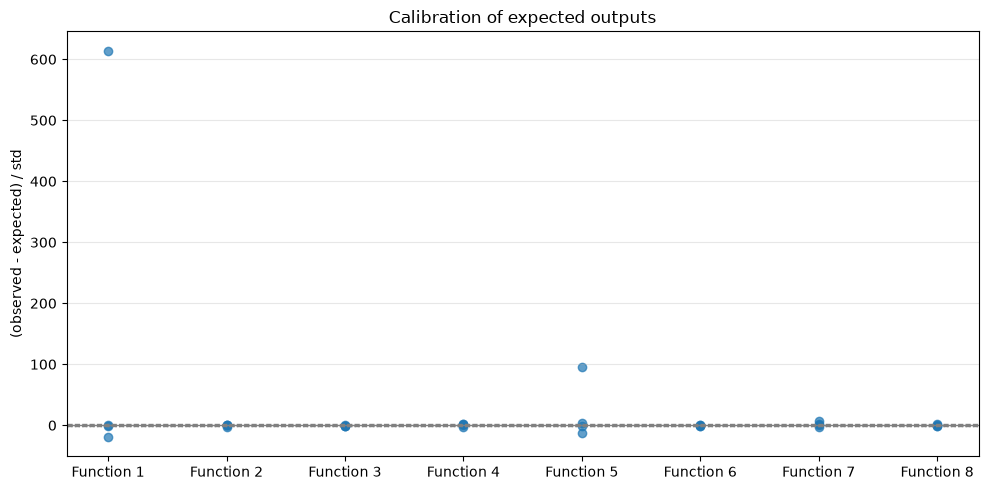

In [5]:
calibration_figure, calibration_ax = plot_calibration(residuals)
display(calibration_figure)
plt.close(calibration_figure)